# 정상 타일에 균열 데이터 만들기

컴퓨터비전 실습 · Stable Diffusion Inpainting

정상 타일 이미지에 균열을 추가하는 작은 실험으로 주제를 정했다.
이미지 전체를 새로 만들기보다는 원래 표면을 남기면서 일부 영역만 바꾸는 쪽이 제조 결함 데이터 생성에 더 적절하다고 생각했다.

정상 이미지 2장에 시드 2개와 생성 강도 2개를 적용해 총 8장을 비교하는 구성이다.
모델 학습보다는 **결함이 생기는 영역을 제어하고, 생성 조건의 차이를 해석하는 것**에 초점을 맞췄다.

## 1 주제와 실험 질문

이번에 비교할 질문은 **같은 타일과 같은 마스크에서 strength 0.65와 0.95가 어떤 차이를 만드는가**이다.
타일 표면은 물체의 위치나 자세를 맞추는 과정 없이 균열과 주변 질감을 비교할 수 있어서 첫 실습 대상으로 골랐다.

전체를 생성하면 균열뿐 아니라 배경과 질감도 바뀔 수 있다. 그래서 수정할 영역을 마스크로 지정하는 inpainting을 선택했다.
원본·마스크·시드를 고정하고 strength만 바꾸면 여러 조건이 한꺼번에 달라지는 문제를 줄일 수 있다고 판단했다.

처음 예상은 강도를 높이면 균열이 더 뚜렷해질 수 있지만 주변 질감과 어울리지 않을 가능성도 커진다는 것이다.
이번 범위는 생성 결과의 변화와 사용 가능성을 살펴보는 데까지로 잡았다. 검사 모델의 정확도는 별도 실험이 필요하다.

## 2 실행 환경

실행 환경은 VS Code에 연결하는 Colab GPU로 정했다. Jupyter와 Google Colab 확장을 사용하고,
커널은 `Select Kernel → Colab → Auto Connect`에서 연결하는 구성이다.

Colab의 기존 GPU용 PyTorch와 CUDA는 그대로 두고, Diffusers와 관련 패키지만 맞췄다.
GPU 장치명과 패키지 버전도 결과와 함께 저장하도록 했다. 같은 코드를 다른 환경에서 실행할 때 차이가 생기는지 확인하기 위한 기록이다.

해상도는 512×512, 생성 배치는 1장으로 잡았다. 모델은 CPU offload를 적용해 필요한 부분만 GPU에 올리도록 구성했다.

In [64]:
# Colab에 있는 torch는 유지하고 생성에 필요한 패키지만 맞췄다.
import sys
import subprocess

packages = [
    "diffusers==0.35.1", "transformers==4.56.2", "accelerate==1.10.1",
    "huggingface-hub==0.34.4", "safetensors>=0.4.3,<1", "peft==0.17.1",
    "numpy>=1.26,<3", "pandas>=2.1,<4", "Pillow>=10,<14",
    "matplotlib>=3.8,<4", "requests>=2.31,<3",
]
subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet", *packages])
print("패키지 준비 완료")


패키지 준비 완료


In [65]:
from pathlib import Path
from datetime import datetime, timezone, timedelta
from importlib.metadata import version
import hashlib
import io
import json
import platform
import shutil
import time

import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw, ImageFilter, ImageChops, ImageOps
from IPython.display import display, Markdown, FileLink

def save_json(path, value):
    Path(path).write_text(json.dumps(value, ensure_ascii=False, indent=2), encoding="utf-8")

def sha256_file(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()

print("Python", platform.python_version())


Python 3.13.15


## 3 실험 조건

기본 조건은 아래와 같이 정했다. 먼저 8장만 비교하고, 이후에는 마스크 폭을 바꿔보는 순서로 범위를 나눴다.

| 항목 | 설정 |
| --- | --- |
| 정상 이미지 | tile 2장 |
| 시드 | 17, 42 |
| 생성 강도 | 0.65, 0.95 |
| 이미지 크기 | 512×512 |
| 마스크 폭 | 36px |
| 요청 추론 단계 | 30 |
| guidance scale | 7.5 |

프롬프트에는 얇고 불규칙한 균열, 같은 재질과 조명을 넣었다.
타일이 크게 부서지거나 새로운 물체가 생기는 방향은 이번 목표와 달라서 negative prompt에 포함했다.

In [66]:
NUM_NORMALS = 2
SEEDS = [17, 42]
STRENGTHS = [0.65, 0.95]
IMAGE_SIZE = 512
MASK_WIDTH = 36
NUM_STEPS = 30
GUIDANCE_SCALE = 7.5

PROMPT = (
    "a close-up inspection photograph of a gray speckled ceramic tile surface "
    "with one thin irregular dark crack, a realistic hairline fracture in the tile, "
    "same material and lighting, industrial inspection"
)
NEGATIVE_PROMPT = (
    "text, watermark, drawing, cartoon, blurry, hole, missing tile, "
    "large broken pieces, colorful paint, new objects"
)
MODEL_ID = "stable-diffusion-v1-5/stable-diffusion-inpainting"
MODEL_REVISION = "8a4288a76071f7280aedbdb3253bdb9e9d5d84bb"
DATA_REPO = "Voxel51/mvtec-ad"
DATA_REVISION = "30a183a3b96e3aef953f230784b123b719b09d97"
# 미러의 samples.json에서 정상 tile 학습 이미지로 확인한 경로를 고정했다.
DATA_FILES = [
    {"path": "data/data_21/000-45.png", "sha256": "522535bee0cc7e38a853dbdab79302f99f2f0f7fe66533e386f1b0c558ce5d0b"},
    {"path": "data/data_21/001-45.png", "sha256": "52199e4b50f6f4810ec40ade431de5942e5359de9e8eca70e4d817b14786fc0e"},
]

assert 1 <= NUM_NORMALS <= len(DATA_FILES)
assert IMAGE_SIZE >= 256 and IMAGE_SIZE % 8 == 0
assert len(SEEDS) == len(set(SEEDS)) and len(SEEDS) > 0
assert len(STRENGTHS) == len(set(STRENGTHS)) and len(STRENGTHS) >= 2
assert len({f"{s:.3f}" for s in STRENGTHS}) == len(STRENGTHS), "강도는 소수 셋째 자리까지 서로 다르게 설정하세요."
assert all(0 < s <= 1 and int(NUM_STEPS * s) >= 1 for s in STRENGTHS)
assert 1 <= MASK_WIDTH <= IMAGE_SIZE // 4

KST = timezone(timedelta(hours=9))
RUNS_ROOT = (Path("/content") if Path("/content").is_dir() else Path.cwd()) / "tile_crack_runs"
RUN_DIR = RUNS_ROOT / datetime.now(KST).strftime("%Y%m%d_%H%M%S_%f")
for folder in ["inputs", "masks", "raw", "images", "figures"]:
    (RUN_DIR / folder).mkdir(parents=True, exist_ok=True)

config = {
    "model_id": MODEL_ID, "model_revision": MODEL_REVISION,
    "data_repo": DATA_REPO, "data_revision": DATA_REVISION,
    "num_normals": NUM_NORMALS, "seeds": SEEDS, "strengths": STRENGTHS,
    "image_size": IMAGE_SIZE, "mask_width": MASK_WIDTH,
    "num_inference_steps": NUM_STEPS, "guidance_scale": GUIDANCE_SCALE,
    "prompt": PROMPT, "negative_prompt": NEGATIVE_PROMPT,
    "mask_seed": 2026, "feather_radius": 3,
    "started_at": datetime.now(KST).isoformat(),
}
save_json(RUN_DIR / "config.json", config)
print(f"생성 예정: {NUM_NORMALS * len(SEEDS) * len(STRENGTHS)}장")
print("저장 폴더:", RUN_DIR)


생성 예정: 8장
저장 폴더: /content/tile_crack_runs/20261018_220540_973380


## 4 정상 이미지와 생성 영역

입력은 MVTec AD의 tile 정상 학습 이미지 2장으로 정했다. 작은 실험이라 전체 데이터셋 대신 공개 미러에서 필요한 파일만 받도록 했다.
미러의 파일명은 원본과 달라서 `samples.json`의 category, split, defect를 기준으로 경로를 확인했다.

같은 입력으로 다시 비교할 수 있도록 데이터 버전과 파일 해시를 고정했다.
실제 결함 테스트 이미지는 이번 생성 입력에 포함하지 않았다. 이미지와 변형 결과의 사용 조건은 CC BY-NC-SA 4.0이다.

In [67]:
def download_checked(url, target, expected_hash):
    target = Path(target)
    if not target.exists() or sha256_file(target) != expected_hash:
        last_error = None
        for attempt in range(3):
            try:
                response = requests.get(url, timeout=(15, 90))
                response.raise_for_status()
                content = response.content
                if hashlib.sha256(content).hexdigest() != expected_hash:
                    raise ValueError("원본 파일 해시가 다릅니다. 데이터 주소와 버전을 확인하세요.")
                with Image.open(io.BytesIO(content)) as candidate:
                    candidate.verify()
                target.write_bytes(content)
                break
            except (requests.RequestException, ValueError, OSError) as exc:
                last_error = exc
                if attempt == 2:
                    raise RuntimeError("정상 이미지 다운로드 실패. 인터넷 연결을 확인하고 이 셀을 다시 실행하세요.") from last_error
                time.sleep(attempt + 1)
    return target

sources, input_metadata = [], []
for i, item in enumerate(DATA_FILES[:NUM_NORMALS]):
    url = f"https://huggingface.co/datasets/{DATA_REPO}/resolve/{DATA_REVISION}/{item['path']}"
    original = download_checked(url, RUN_DIR / "inputs" / f"tile_{i:02d}_original.png", item["sha256"])
    with Image.open(original) as image:
        image = ImageOps.exif_transpose(image).convert("RGB")
        resized = ImageOps.fit(image, (IMAGE_SIZE, IMAGE_SIZE), method=Image.Resampling.LANCZOS)
    resized_path = RUN_DIR / "inputs" / f"tile_{i:02d}.png"
    resized.save(resized_path)
    sources.append(resized)
    input_metadata.append({
        "source_id": f"tile_{i:02d}", "url": url, "source_sha256": item["sha256"],
        "category": "tile", "split": "train", "defect": "good",
        "resized_path": str(resized_path.relative_to(RUN_DIR)),
        "resized_sha256": sha256_file(resized_path),
        "license": "CC BY-NC-SA 4.0", "mirror_path": item["path"],
    })
save_json(RUN_DIR / "input_manifest.json", input_metadata)
attribution = """MVTec AD tile images, Paul Bergmann et al., CVPR 2019.
Original dataset: https://www.mvtec.com/research-teaching/datasets/mvtec-ad
Mirror: https://huggingface.co/datasets/Voxel51/mvtec-ad
Dataset and adapted images: CC BY-NC-SA 4.0, non-commercial educational use.
License: https://creativecommons.org/licenses/by-nc-sa/4.0/
Changes: 512px resize, localized AI-generated crack and alpha compositing.
Model: stable-diffusion-v1-5/stable-diffusion-inpainting (CreativeML OpenRAIL-M).
All generated defect images are synthetic. Edit masks are not precise defect annotations.
"""
(RUN_DIR / "DATA_LICENSE_AND_SOURCES.txt").write_text(attribution, encoding="utf-8")
print(f"정상 이미지 {len(sources)}장 준비 완료")


정상 이미지 2장 준비 완료


tile_00: 생성 요청 영역 = 전체의 5.11%
tile_01: 생성 요청 영역 = 전체의 5.01%


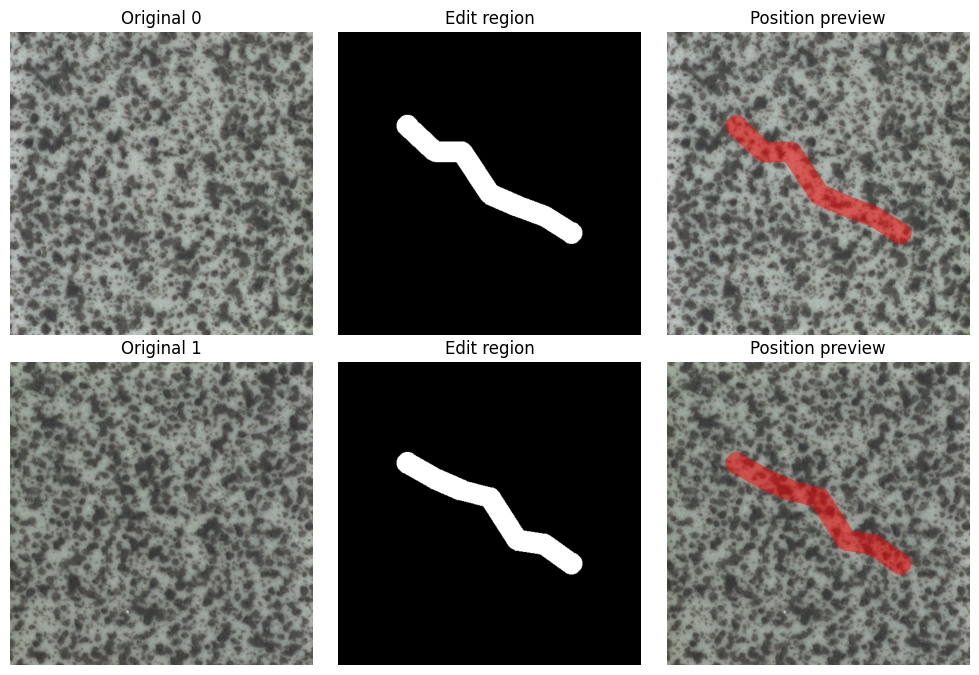

In [68]:
def make_edit_mask(size, width, seed):
    # 균열이 생길 범위를 먼저 잡았다. 이 영역 전체가 결함 정답인 것은 아니다.
    rng = np.random.default_rng(seed)
    xs = np.linspace(size * 0.23, size * 0.77, 7)
    ys = np.linspace(size * 0.33, size * 0.67, 7) + rng.normal(0, size * 0.025, 7)
    points = [(int(x), int(y)) for x, y in zip(xs, ys)]
    mask = Image.new("L", (size, size), 0)
    draw = ImageDraw.Draw(mask)
    draw.line(points, fill=255, width=width, joint="curve")
    radius = width // 2
    for x, y in [points[0], points[-1]]:
        draw.ellipse((x-radius, y-radius, x+radius, y+radius), fill=255)
    return mask

def feather_inside(mask, radius=3):
    # 경계는 안쪽으로만 부드럽게 했다. 밖으로 번지면 정상 표면까지 바뀔 수 있다.
    return ImageChops.multiply(mask, mask.filter(ImageFilter.GaussianBlur(radius)))

def composite_local(original, generated, mask):
    return Image.composite(generated.convert("RGB"), original.convert("RGB"), feather_inside(mask))

masks = [make_edit_mask(IMAGE_SIZE, MASK_WIDTH, 2026+i) for i in range(len(sources))]
fig, axes = plt.subplots(len(sources), 3, figsize=(10, 3.4 * len(sources)), squeeze=False)
for i, (image, mask) in enumerate(zip(sources, masks)):
    mask.save(RUN_DIR / "masks" / f"tile_{i:02d}_edit_region.png")
    feather_inside(mask).save(RUN_DIR / "masks" / f"tile_{i:02d}_alpha.png")
    overlay = Image.blend(image, Image.new("RGB", image.size, "red"), 0.5)
    overlay = Image.composite(overlay, image, mask)
    for ax, view, title in zip(axes[i], [image, mask, overlay], [f"Original {i}", "Edit region", "Position preview"]):
        ax.imshow(view, cmap="gray" if view.mode == "L" else None)
        ax.set_title(title); ax.axis("off")
    area = (np.array(mask) > 0).mean() * 100
    print(f"tile_{i:02d}: 생성 요청 영역 = 전체의 {area:.2f}%")
fig.tight_layout()
fig.savefig(RUN_DIR / "figures" / "input_masks.png", dpi=140)
plt.show()


마스크의 흰색은 생성할 영역이고 검은색은 남길 영역이다.
균열이 일직선으로만 생기지 않도록 꺾인 선을 만들고, 그 주변에 폭을 주는 방식으로 잡았다.

여기서 마스크는 결함을 직접 그린 그림이 아니라 **모델이 수정할 수 있는 범위**다.
실제로 균열이 생긴 픽셀과 일치하는 정답 라벨로 볼 수는 없다.

## 5 모델 준비

사전 학습된 Stable Diffusion Inpainting 가중치로 추론하는 방식이다.
fp16 가중치와 CPU offload를 사용하고, 안전 검사기는 기본 설정을 유지했다.

offload가 장치 이동을 관리하므로 모델 전체를 따로 GPU로 옮기는 코드는 넣지 않았다.
노이즈 제거 스케줄러는 DPM-Solver로 정하고 설정도 별도로 저장하도록 했다.

In [69]:
import torch

if not torch.cuda.is_available():
    raise RuntimeError("GPU가 없습니다. VS Code 커널이 Colab GPU 서버인지 확인하세요. 로컬 Python 커널이면 Colab으로 바꿔 주세요.")

torch.manual_seed(2026)
torch.backends.cudnn.benchmark = False
torch.backends.cuda.matmul.allow_tf32 = False
gpu_name = torch.cuda.get_device_name(0)
gpu_gb = torch.cuda.get_device_properties(0).total_memory / 1024**3
print(f"GPU: {gpu_name} ({gpu_gb:.1f} GB)")
print("PyTorch:", torch.__version__, "CUDA:", torch.version.cuda)
environment = {
    "python": platform.python_version(), "torch": torch.__version__,
    "cuda": torch.version.cuda, "gpu": gpu_name, "gpu_memory_gb": gpu_gb,
    "packages": {name: version(name) for name in [
        "diffusers", "transformers", "accelerate", "huggingface-hub", "safetensors", "numpy", "Pillow", "pandas", "matplotlib"
    ]},
}
save_json(RUN_DIR / "environment.json", environment)
# 같은 시드라도 환경에 따라 차이가 날 수 있어서 패키지 버전까지 남겼다.
frozen = subprocess.check_output([sys.executable, "-m", "pip", "freeze"], text=True)
(RUN_DIR / "environment_freeze.txt").write_text(frozen, encoding="utf-8")


GPU: NVIDIA A100-SXM4-80GB (79.3 GB)
PyTorch: 2.11.0+cu130 CUDA: 13.0


14591

In [70]:
from diffusers import StableDiffusionInpaintPipeline, DPMSolverMultistepScheduler

load_started = time.perf_counter()
pipe = StableDiffusionInpaintPipeline.from_pretrained(
    MODEL_ID, revision=MODEL_REVISION,
    torch_dtype=torch.float16, variant="fp16", use_safetensors=True,
)
pipe.scheduler = DPMSolverMultistepScheduler.from_config(pipe.scheduler.config)
pipe.enable_model_cpu_offload()
pipe.enable_vae_slicing()
config["scheduler"] = type(pipe.scheduler).__name__
save_json(RUN_DIR / "scheduler_config.json", dict(pipe.scheduler.config))
config["model_load_seconds"] = round(time.perf_counter() - load_started, 2)
save_json(RUN_DIR / "config.json", config)
print("모델 준비 완료:", config["model_load_seconds"], "초")


model_index.json:   0%|          | 0.00/548 [00:00<?, ?B/s]

Fetching 16 files:   0%|          | 0/16 [00:00<?, ?it/s]

config.json:   0%|          | 0.00/617 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/748 [00:00<?, ?B/s]

config.json: 0.00B [00:00, ?B/s]

...

config.json:   0%|          | 0.00/552 [00:00<?, ?B/s]

unet/diffusion_pytorch_model.fp16.safete(…):   0%|          | 0.00/1.72G [00:00<?, ?B/s]

vae/diffusion_pytorch_model.fp16.safeten(…):   0%|          | 0.00/167M [00:00<?, ?B/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

모델 준비 완료: 9.14 초


## 6 강도별 이미지 생성

같은 원본·마스크·시드에서 두 강도를 비교하도록 반복문을 구성했다.
조건마다 난수 생성기를 같은 시드로 다시 초기화해, 앞선 생성에서 난수가 소모된 영향이 다음 조건에 이어지지 않게 했다.

strength가 바뀌면 시작 타임스텝과 실제 노이즈 제거 횟수도 달라진다.
요청 단계는 둘 다 30이지만 기본 조건에서 실제 반복은 각각 19회와 28회이므로, 실행 시간 차이를 강도만의 효과로 해석하기는 어렵다.

원출력은 `raw`, 마스크 바깥을 원본으로 복원한 결과는 `images`에 따로 저장한다.
두 이미지를 구분해 두면 모델이 만든 변화와 합성 과정에서 보존한 부분을 함께 살펴볼 수 있다.

In [71]:
def measure_changes(original, raw, final, mask):
    a = np.asarray(original, dtype=np.float32)
    b = np.asarray(raw, dtype=np.float32)
    c = np.asarray(final, dtype=np.float32)
    region = np.asarray(mask) > 0
    assert region.any() and (~region).any()
    return {
        "mask_fraction": float(region.mean()),
        "raw_inside_mae": float(np.abs(b-a)[region].mean()),
        "raw_outside_mae": float(np.abs(b-a)[~region].mean()),
        "final_inside_mae": float(np.abs(c-a)[region].mean()),
        "final_outside_mae": float(np.abs(c-a)[~region].mean()),
        "final_outside_max": float(np.abs(c-a)[~region].max()),
    }

def write_table(records):
    pd.DataFrame(records).to_csv(RUN_DIR / "metrics.csv", index=False, encoding="utf-8-sig")
    save_json(RUN_DIR / "generation_manifest.json", records)

records = []
for image_idx, (original, mask) in enumerate(zip(sources, masks)):
    for seed in SEEDS:
        for strength in STRENGTHS:
            sample_id = f"tile_{image_idx:02d}_seed{seed}_strength{strength:.3f}"
            generator = torch.Generator(device="cpu").manual_seed(seed)
            torch.cuda.synchronize()
            started = time.perf_counter()
            try:
                # 같은 시드에서 다시 시작해 이전 생성의 난수 상태가 이어지지 않게 했다.
                with torch.inference_mode():
                    prediction = pipe(
                        prompt=PROMPT, negative_prompt=NEGATIVE_PROMPT,
                        image=original, mask_image=mask,
                        height=IMAGE_SIZE, width=IMAGE_SIZE,
                        strength=float(strength), num_inference_steps=NUM_STEPS,
                        guidance_scale=GUIDANCE_SCALE, generator=generator,
                        num_images_per_prompt=1,
                        # 원출력의 주변 변화도 보려고 자동 crop 합성은 사용하지 않았다.
                        padding_mask_crop=None, output_type="pil",
                    )
                torch.cuda.synchronize()
            except torch.cuda.OutOfMemoryError as exc:
                raise RuntimeError("GPU 메모리 부족. 커널을 재시작하고 다른 GPU 모델을 올리지 않은 상태에서 다시 실행하세요.") from exc
            elapsed = time.perf_counter() - started
            flags = prediction.nsfw_content_detected
            blocked = bool(flags[0]) if flags is not None else False
            row = {
                "sample_id": sample_id, "source_id": f"tile_{image_idx:02d}",
                "seed": seed, "strength": strength, "steps_requested": NUM_STEPS,
                "steps_effective": int(pipe.num_timesteps),
                "guidance_scale": GUIDANCE_SCALE, "seconds": round(elapsed, 3),
                "status": "safety_filtered" if blocked else "ok",
                "model_id": MODEL_ID, "model_revision": MODEL_REVISION,
                "prompt": PROMPT, "negative_prompt": NEGATIVE_PROMPT,
                "source_path": input_metadata[image_idx]["resized_path"],
                "edit_region_path": f"masks/tile_{image_idx:02d}_edit_region.png",
            }
            if not blocked:
                raw = prediction.images[0].convert("RGB")
                final = composite_local(original, raw, mask)
                raw_rel, final_rel = f"raw/{sample_id}.png", f"images/{sample_id}.png"
                raw.save(RUN_DIR / raw_rel); final.save(RUN_DIR / final_rel)
                row.update({"raw_path": raw_rel, "image_path": final_rel,
                            "image_sha256": sha256_file(RUN_DIR / final_rel)})
                row.update(measure_changes(original, raw, final, mask))
                assert row["final_outside_max"] == 0, "마스크 밖 보존 처리를 확인하세요."
            records.append(row)
            write_table(records)  # 연결이 끊겨도 끝난 샘플의 기록은 남도록 매번 저장했다.
            print(sample_id, row["status"], f"{elapsed:.1f}s")

metrics = pd.DataFrame(records)
ok = metrics.loc[metrics["status"] == "ok"].copy()
if ok.empty:
    raise RuntimeError("유효한 출력이 없습니다. 안전 필터 등 기록된 상태를 확인하세요.")
print(f"완료: 전체 {len(metrics)}장 중 유효한 결과 {len(ok)}장")
display(ok[["sample_id", "strength", "steps_effective", "seconds", "raw_inside_mae", "raw_outside_mae", "final_inside_mae", "final_outside_mae"]].round(3))


  0%|          | 0/19 [00:00<?, ?it/s]

tile_00_seed17_strength0.650 ok 3.6s


  0%|          | 0/28 [00:00<?, ?it/s]

tile_00_seed17_strength0.950 ok 3.2s


  0%|          | 0/19 [00:00<?, ?it/s]

...

  0%|          | 0/19 [00:00<?, ?it/s]

tile_01_seed42_strength0.650 ok 2.8s


  0%|          | 0/28 [00:00<?, ?it/s]

tile_01_seed42_strength0.950 ok 3.1s
완료: 전체 8장 중 유효한 결과 8장


,sample_id,strength,steps_effective,seconds,raw_inside_mae,raw_outside_mae,final_inside_mae,final_outside_mae
0,tile_00_seed17_strength0.650,0.65,19,3.570,22.636,6.638,21.646,0.0
1,tile_00_seed17_strength0.950,0.95,28,3.197,25.291,6.659,24.234,0.0
2,tile_00_seed42_strength0.650,0.65,19,2.724,23.496,6.872,22.358,0.0
3,tile_00_seed42_strength0.950,0.95,28,3.084,26.913,6.931,25.684,0.0
4,tile_01_seed17_strength0.650,0.65,19,2.768,23.314,5.900,22.340,0.0
5,tile_01_seed17_strength0.950,0.95,28,3.110,26.216,5.899,25.181,0.0
6,tile_01_seed42_strength0.650,0.65,19,2.753,23.093,6.134,22.111,0.0
7,tile_01_seed42_strength0.950,0.95,28,3.099,26.422,6.182,25.352,0.0


## 7 조건별 비교

같은 타일과 시드의 결과가 한 줄에 오도록 배치했다. 원본 옆에 두 강도의 결과를 두면 질감과 균열을 비교하기 편할 것 같았다.
비교 그림은 `figures/comparison.png`, 한 장을 자세히 보는 그림은 `figures/detail.png`에 저장된다.

변화량 그림도 함께 남긴다. 눈에 잘 띄는 균열뿐 아니라 주변 표면까지 바뀌었는지를 확인하려는 목적이다.

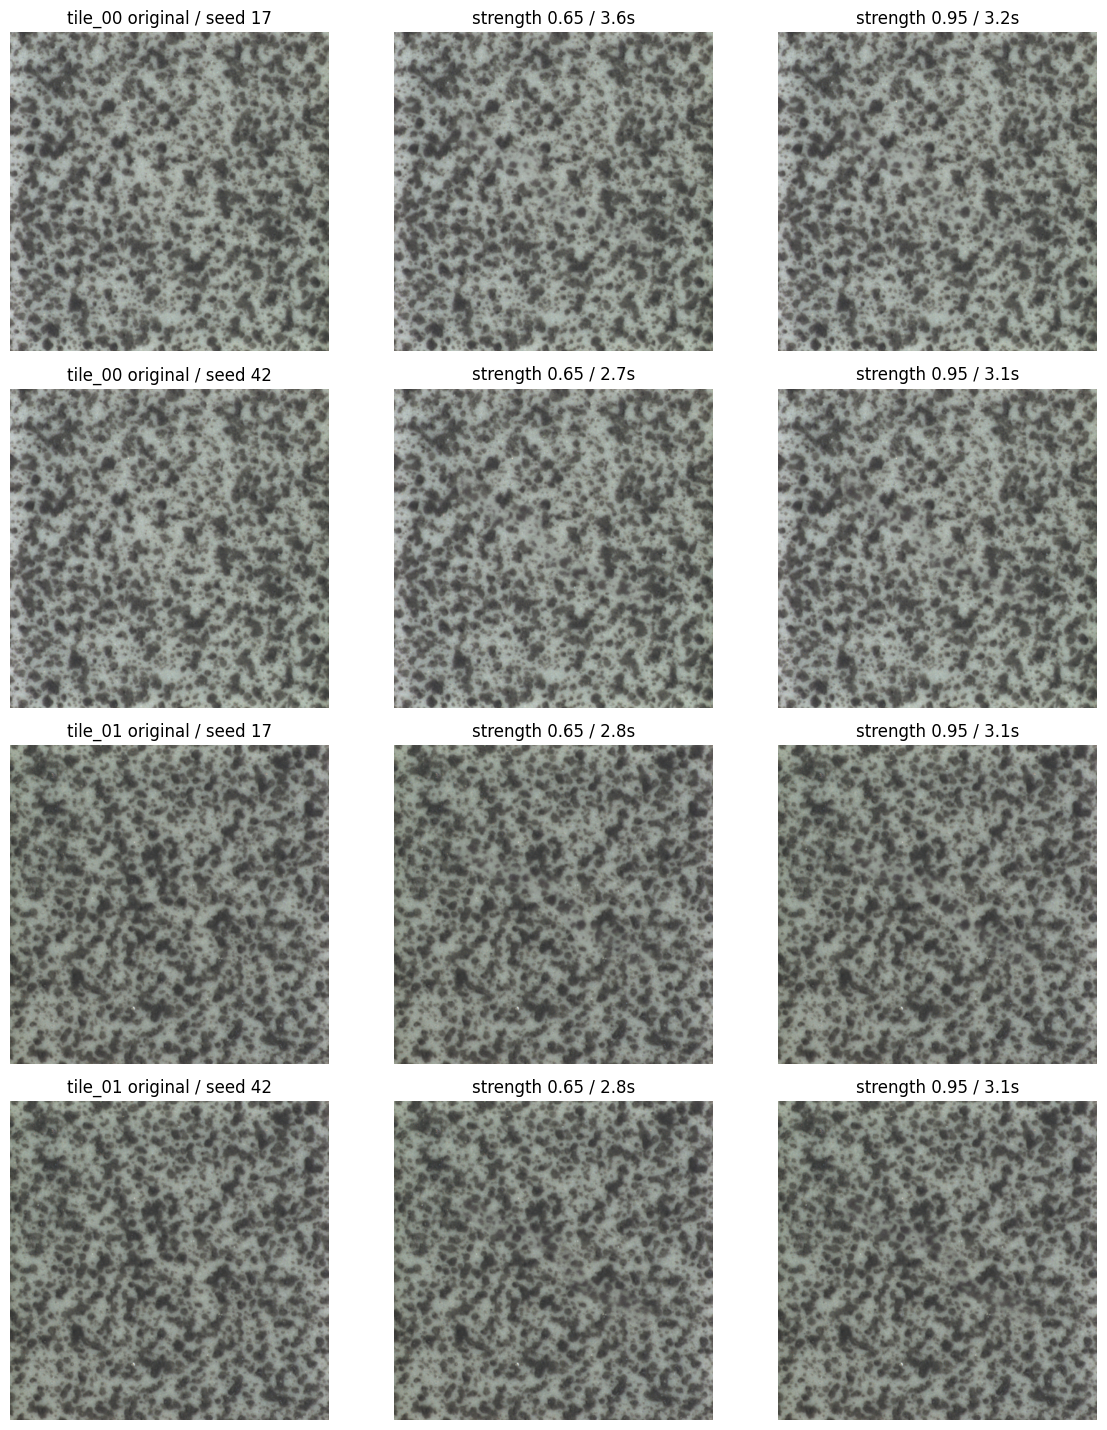

,strength,n,seconds_mean,inside_mae_mean,raw_outside_mae_mean,final_outside_mae_max
0,0.65,4,2.954,22.114,6.386,0.0
1,0.95,4,3.122,25.113,6.418,0.0


In [72]:
pairs = ok[["source_id", "seed"]].drop_duplicates().itertuples(index=False, name=None)
pairs = list(pairs)
fig, axes = plt.subplots(len(pairs), 1+len(STRENGTHS), figsize=(4*(1+len(STRENGTHS)), 3.6*len(pairs)), squeeze=False)
for r, (source_id, seed) in enumerate(pairs):
    image_idx = int(source_id.split("_")[-1])
    axes[r, 0].imshow(sources[image_idx]); axes[r, 0].set_title(f"{source_id} original / seed {seed}")
    for col, strength in enumerate(STRENGTHS, 1):
        selected = ok[(ok.source_id == source_id) & (ok.seed == seed) & np.isclose(ok.strength, strength)]
        if len(selected):
            row = selected.iloc[0]
            with Image.open(RUN_DIR / row.image_path) as image:
                axes[r, col].imshow(image)
            axes[r, col].set_title(f"strength {strength} / {row.seconds:.1f}s")
        else:
            axes[r, col].set_title(f"strength {strength}: no valid output")
    for ax in axes[r]: ax.axis("off")
fig.tight_layout()
fig.savefig(RUN_DIR / "figures" / "comparison.png", dpi=140)
plt.show()

summary = ok.groupby("strength", as_index=False).agg(
    n=("sample_id", "count"), seconds_mean=("seconds", "mean"),
    inside_mae_mean=("final_inside_mae", "mean"),
    raw_outside_mae_mean=("raw_outside_mae", "mean"),
    final_outside_mae_max=("final_outside_mae", "max"),
)
summary.to_csv(RUN_DIR / "summary.csv", index=False, encoding="utf-8-sig")
display(summary.round(3))


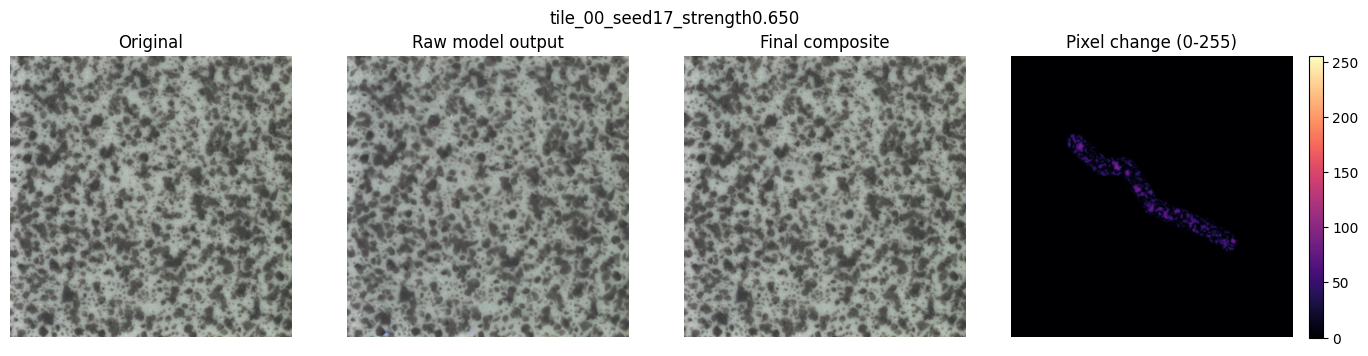

In [73]:
# 첫 결과는 원출력과 합성 결과를 따로 놓고 바뀐 위치까지 비교하도록 했다.
inspect_id = ok.iloc[0]["sample_id"]
selected = ok.loc[ok.sample_id == inspect_id].iloc[0]
image_idx = int(selected.source_id.split("_")[-1])
with Image.open(RUN_DIR / selected.raw_path) as image: raw_view = image.convert("RGB")
with Image.open(RUN_DIR / selected.image_path) as image: final_view = image.convert("RGB")
change = np.abs(np.asarray(final_view, dtype=float)-np.asarray(sources[image_idx], dtype=float)).mean(axis=2)
fig, axes = plt.subplots(1, 4, figsize=(14, 3.5))
for ax, image, title in zip(axes[:3], [sources[image_idx], raw_view, final_view], ["Original", "Raw model output", "Final composite"]):
    ax.imshow(image); ax.set_title(title); ax.axis("off")
heat = axes[3].imshow(change, cmap="magma", vmin=0, vmax=255)
axes[3].set_title("Pixel change (0-255)"); axes[3].axis("off")
fig.colorbar(heat, ax=axes[3], fraction=0.046)
fig.suptitle(inspect_id)
fig.tight_layout(); fig.savefig(RUN_DIR / "figures" / "detail.png", dpi=140)
plt.show()


### 측정값 정리

변화량은 원본과의 RGB 절대 차이 평균으로 계산했다. 값의 범위는 0~255다.

| 측정값 | 이번 실험에서 보는 의미 |
| --- | --- |
| final_inside_mae | 최종 이미지가 수정 영역 안에서 얼마나 달라졌는지 |
| raw_outside_mae | 모델 원출력에서 주변 표면까지 얼마나 바뀌었는지 |
| final_outside_mae | 합성 후 주변 표면이 원본대로 남았는지 |
| seconds | 다운로드와 모델 로딩을 제외한 한 장의 생성 시간 |

내가 가장 조심해서 볼 값은 영역 안 변화량이다. 값이 크면 변화가 많다는 뜻이지 균열이 더 자연스럽다는 뜻은 아니다.
실행 시간도 첫 생성의 예열과 GPU 상태에 영향을 받으므로 참고값으로 두었다.
8장으로 FID나 검사 정확도를 계산하는 것보다, 같은 조건의 결과를 직접 비교하는 편이 이번 규모에 맞다고 생각했다.

## 8 이미지 평가 기준

숫자로 표현하기 어려운 부분은 균열 가시성, 자연스러움, 경계 흔적으로 나눴다.
균열이 선명해도 페인트를 칠한 것처럼 보이면 사용하기 어렵기 때문에 세 항목을 따로 두었다.

| 항목 | 1점 | 2점 | 3점 |
| --- | --- | --- | --- |
| 가시성 visible | 거의 보이지 않음 | 보이지만 애매함 | 균열이 뚜렷함 |
| 자연스러움 natural | 그림이나 페인트처럼 보임 | 판단이 어려움 | 표면 균열처럼 보임 |
| 경계 seam | 합성 경계가 뚜렷함 | 조금 보임 | 거의 보이지 않음 |

점수는 높을수록 좋은 쪽으로 맞췄다. 이미지별 점수와 판단 근거는 `my_review.csv`로 묶이도록 했다.

In [74]:
my_reviews = {
}

review_rows = []
for sample_id in ok.sample_id:
    review = my_reviews.get(sample_id, {})
    for key in ["visible", "natural", "seam"]:
        value = review.get(key)
        if value is not None and value not in (1, 2, 3):
            raise ValueError(f"{sample_id}: {key} 점수는 1, 2, 3 중 하나입니다.")
    review_rows.append({"sample_id": sample_id, **{key: review.get(key) for key in ["visible", "natural", "seam", "note"]}})
reviews = pd.DataFrame(review_rows)
reviews.to_csv(RUN_DIR / "my_review.csv", index=False, encoding="utf-8-sig")
display(reviews)
print("직접 평가한 결과:", int(reviews[["visible", "natural", "seam"]].notna().all(axis=1).sum()), "/", len(reviews))


,sample_id,visible,natural,seam,note
0,tile_00_seed17_strength0.650,None,None,None,None
1,tile_00_seed17_strength0.950,None,None,None,None
2,tile_00_seed42_strength0.650,None,None,None,None
3,tile_00_seed42_strength0.950,None,None,None,None
4,tile_01_seed17_strength0.650,None,None,None,None
5,tile_01_seed17_strength0.950,None,None,None,None
6,tile_01_seed42_strength0.650,None,None,None,None
7,tile_01_seed42_strength0.950,None,None,None,None


직접 평가한 결과: 0 / 8


### 결과 해석

이번 구성에서는 **영역 안의 변화량과 균열의 자연스러움을 분리해서 보는 것**이 핵심이라고 생각했다.
강도를 높여 변화량이 커지더라도, 그 변화가 균열인지 얼룩이나 질감 손상인지는 이미지로 판단해야 한다.
그래서 변화량이 가장 큰 조건을 곧바로 가장 좋은 조건으로 고르는 방식은 사용하지 않았다.

마스크 밖 변화량은 원출력과 최종 결과를 나눠 해석했다.
최종 결과의 바깥 변화가 0이 되는 것은 그 영역에 원본 픽셀을 사용하도록 만든 합성 방식의 결과다.
이 수치를 모델이 정상 표면을 완벽하게 보존했다는 근거로 쓰면 후처리 효과를 모델 성능으로 착각하게 된다.

또한 강도가 높아지면 실제 반복 횟수도 늘어난다. 시간 비교에는 이 차이가 함께 들어가므로,
이번 실험은 순수한 속도 비교보다 두 강도에서 얻는 이미지 변화의 차이를 보는 데 의미를 두었다.
수치 비교는 이어지는 셀에서 저장된 결과를 기준으로 계산하도록 연결했다.

### 피드백

구성을 다시 살펴보니 마스크를 만들었다는 이유만으로 결함 라벨까지 확보했다고 생각하기 쉬운 부분이 있었다.
하지만 마스크 안 전체가 실제 균열로 채워지는 것은 아니므로, 생성 영역과 결함 정답은 구분하는 편이 맞다.
이번에는 생성 영역이라는 이름으로만 저장하도록 정리했다.

또 정상 이미지가 2장이고 시드도 2개라서, 한 조건이 좋아 보이더라도 다른 표면에서 같은 경향이 나올지는 확신하기 어렵다.
우선 작은 실험에서 조건의 영향을 파악하고, 데이터가 실제 검사 학습에 도움이 되는지는 따로 확인하는 것이 낫다고 판단했다.

In [75]:
# 조건별 수치와 같은 원본·시드의 차이를 문장으로도 남겼다.
analysis_lines = ["### 실행 결과 수치 해석", ""]
for item in summary.itertuples(index=False):
    analysis_lines.append(
        f"- strength {item.strength:g}: {int(item.n)}장, 영역 안 평균 변화량 "
        f"{item.inside_mae_mean:.2f}/255, 원출력의 영역 밖 평균 변화량 "
        f"{item.raw_outside_mae_mean:.2f}/255, 평균 생성 시간 {item.seconds_mean:.2f}초."
    )

low_strength, high_strength = min(STRENGTHS), max(STRENGTHS)
paired = ok.pivot(index=["source_id", "seed"], columns="strength", values="final_inside_mae")
if low_strength in paired.columns and high_strength in paired.columns:
    complete_pairs = paired.dropna(subset=[low_strength, high_strength])
    if not complete_pairs.empty:
        differences = complete_pairs[high_strength] - complete_pairs[low_strength]
        increased = int((differences > 0).sum())
        analysis_lines.extend([
            "",
            f"같은 원본·시드의 {len(complete_pairs)}쌍을 비교했을 때, 강도를 "
            f"{low_strength:g}에서 {high_strength:g}로 높인 조건의 영역 안 변화량은 "
            f"평균 {differences.mean():+.2f}/255만큼 달랐다. "
            f"이 중 {increased}쌍에서 변화량이 증가했다.",
        ])

outside_max = float(ok["final_outside_max"].max())
analysis_lines.extend([
    "",
    f"최종 이미지에서 마스크 밖 최대 픽셀 차이는 {outside_max:.0f}이었다. "
    "이 값은 원본을 다시 합성하는 보존 처리의 결과로 해석했다.",
    "변화량만으로 균열의 자연스러움이나 실제 결함과의 유사성을 결정할 수는 없다.",
])

scored = reviews.dropna(subset=["visible", "natural", "seam"])
if not scored.empty:
    judged = scored.merge(ok[["sample_id", "strength"]], on="sample_id")
    score_summary = judged.groupby("strength")[["visible", "natural", "seam"]].mean()
    analysis_lines.extend(["", "이미지 평가 점수는 기록된 샘플만 묶어서 비교했다."])
    for strength, values in score_summary.iterrows():
        count = int(judged["strength"].eq(strength).sum())
        analysis_lines.append(
            f"- strength {strength:g}, 평가 {count}장: 가시성 {values.visible:.2f}, "
            f"자연스러움 {values.natural:.2f}, 경계 {values.seam:.2f}점."
        )
else:
    analysis_lines.extend(["", "이미지 평가 점수는 아직 기록되지 않아 수치 변화만 비교했다."])

result_interpretation = "\n".join(analysis_lines)
(RUN_DIR / "result_interpretation.md").write_text(result_interpretation, encoding="utf-8")
display(Markdown(result_interpretation))


### 실행 결과 수치 해석

- strength 0.65: 4장, 영역 안 평균 변화량 22.11/255, 원출력의 영역 밖 평균 변화량 6.39/255, 평균 생성 시간 2.95초.
- strength 0.95: 4장, 영역 안 평균 변화량 25.11/255, 원출력의 영역 밖 평균 변화량 6.42/255, 평균 생성 시간 3.12초.

같은 원본·시드의 4쌍을 비교했을 때, 강도를 0.65에서 0.95로 높인 조건의 영역 안 변화량은 평균 +3.00/255만큼 달랐다. 이 중 4쌍에서 변화량이 증가했다.

최종 이미지에서 마스크 밖 최대 픽셀 차이는 0이었다. 이 값은 원본을 다시 합성하는 보존 처리의 결과로 해석했다.
변화량만으로 균열의 자연스러움이나 실제 결함과의 유사성을 결정할 수는 없다.

이미지 평가 점수는 아직 기록되지 않아 수치 변화만 비교했다.

## 9 KPT 회고와 다음 행동

### Keep

실험 변수를 하나로 좁힌 구성은 유지하고 싶다. 원본, 마스크, 시드를 묶어두면 어떤 조건이 바뀌었는지 설명하기 쉽다.
원출력과 최종 합성 결과를 따로 남기고, 설정·시드·환경을 이미지와 함께 저장하는 방식도 계속 사용할 생각이다.
결과 그림만 남기는 것보다 다시 비교하거나 원인을 찾아볼 근거가 분명하다.

### Problem

일반 이미지로 사전 학습된 모델이 산업 현장의 균열 특성을 충분히 표현하는지는 이번 구성만으로 확인하기 어렵다.
픽셀 차이 역시 결함의 사실성을 직접 측정하지 못한다.
또 수동으로 정한 마스크의 모양과 폭이 결과에 영향을 줄 수 있는데, 현재 비교에서는 그 부분을 고정해 두었다.
강도에 따른 차이를 해석할 때 마스크 조건에 의존한 결과일 가능성도 함께 생각해야 한다.

### Try

다음에는 프롬프트를 더 복잡하게 만들기보다 **마스크 폭 하나만 바꿔보려 한다**.
36px와 18px를 비교하면 수정 범위를 좁혔을 때 주변 질감과 경계가 더 자연스러워지는지 볼 수 있다.
너무 좁으면 균열이 잘 드러나지 않을 수도 있으므로 경계 점수와 가시성을 함께 비교할 생각이다.

### 다음 행동

1. 첫 8장 비교를 마친 뒤, 동일한 GPU 환경에서 `MASK_WIDTH`만 36에서 18로 바꾼다.
2. 원본 2장, 시드 17·42, strength 0.65·0.95, 30단계와 프롬프트를 그대로 두고 8장을 추가 생성한다.
3. 같은 원본·시드·강도끼리 폭 36과 18의 결과를 짝지어 비교한다.
4. 경계 흔적 점수의 평균은 올라가고 가시성 점수의 평균은 낮아지지 않는지를 확인한다. 이것을 이번 추가 실험의 개선 기준으로 잡았다.
5. 폭을 줄였는데 균열이 흐려진다면 다음 비교에서는 폭 24px를 사용한다. 프롬프트 변경은 이 비교가 끝난 뒤 별도로 진행한다.

## 10 결과 보관

실행마다 다른 폴더를 만들어 입력, 마스크, 원출력, 최종 이미지와 측정표가 섞이지 않도록 했다.
Colab 세션이 끝나면 파일이 사라질 수 있어서 결과 폴더를 ZIP으로 묶고, 필요하면 Drive에도 복사하는 구조다.
ipynb는 이 ZIP과 별개라 VS Code의 노트북 파일로 남는다.

GitHub에는 노트북과 함께 비교 그림, 측정표, 이미지 평가표, 해석, 설정과 환경 기록을 남기는 범위로 정리했다.
모델 가중치와 전체 데이터셋은 제외했다. 비교 그림에 들어간 원본과 변형 이미지의 MVTec 출처 및 CC BY-NC-SA 4.0 조건도 함께 남겼다.

In [76]:
# 결과 폴더를 한 번에 묶었다. 노트북 파일은 이 폴더와 별개다.
archive_path = Path(shutil.make_archive(str(RUN_DIR), "zip", root_dir=RUN_DIR))
print("결과 ZIP:", archive_path)
display(FileLink(str(archive_path)))
print("이미지, 측정표, 설정과 해석 저장 완료")


결과 ZIP: /content/tile_crack_runs/20261018_220540_973380.zip


/content/tile_crack_runs/20261018_220540_973380.zip

이미지, 측정표, 설정과 해석 저장 완료


In [77]:
# Drive 복사도 가능하게 두었고, 기본값은 결과 ZIP만 만드는 것으로 정했다.
SAVE_TO_DRIVE = False
if SAVE_TO_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    drive_output = Path("/content/drive/MyDrive/tile_crack_results")
    drive_output.mkdir(parents=True, exist_ok=True)
    copied = shutil.copy2(archive_path, drive_output / archive_path.name)
    print("Drive에 복사:", copied)


## 참고 자료

- 수업 제공 PDF와 실습 ipynb에서 생성형 AI를 이용한 결함 생성과 inpainting 개념을 참고했다. 이번 코드는 공식 Diffusers API로 작은 조건 비교 실험을 구성했다.
- [MVTec AD](https://www.mvtec.com/research-teaching/datasets/mvtec-ad), Paul Bergmann 외, CVPR 2019. 정상 tile 이미지를 사용했다. 원본과 변형 이미지는 **CC BY-NC-SA 4.0**이며 비상업 교육 목적이다. 변형 내용은 512px 크기 조정과 국소 균열 생성·합성이다.
- [Voxel51/mvtec-ad 공개 미러](https://huggingface.co/datasets/Voxel51/mvtec-ad). 입력 경로와 원본 해시는 `input_manifest.json`에 남긴다.
- [Stable Diffusion Inpainting 모델 카드](https://huggingface.co/stable-diffusion-v1-5/stable-diffusion-inpainting). 기존 Runway 모델의 미러이며 CreativeML OpenRAIL-M 조건을 따른다.
- [Diffusers 0.35.1 inpainting API](https://huggingface.co/docs/diffusers/v0.35.1/en/api/pipelines/stable_diffusion/inpaint). 마스크와 strength 설정을 참고했다.
- [Diffusers 메모리 절약 안내](https://huggingface.co/docs/diffusers/v0.35.1/en/optimization/memory). 모델 CPU offload 설정을 참고했다.
- [Google Colab VS Code 확장](https://github.com/googlecolab/colab-vscode). Colab 커널 연결에 사용한다.